In [1]:
# TASK 1: Installing required libraries

!pip install -q kagglehub opencv-python-headless scikit-learn seaborn matplotlib

In [2]:
# TASK 1: Downloading URFD dataset from Kaggle

import kagglehub
import os

# Download dataset
dataset_path = kagglehub.dataset_download(
    "shahliza27/ur-fall-detection-dataset"
)

print("Dataset downloaded successfully!")
print("Dataset location:", dataset_path)

100%|██████████| 4.18G/4.18G [01:05<00:00, 68.5MB/s]

Extracting files...


Dataset downloaded successfully!
Dataset location: /root/.cache/kagglehub/datasets/shahliza27/ur-fall-detection-dataset/versions/1


In [3]:
# TASK 1: Exploring and extracting dataset

import os
import zipfile

data_path = dataset_path

# Extract all ZIP files
for root, dirs, files in os.walk(data_path):

    for file in files:

        if file.lower().endswith(".zip"):

            zip_path = os.path.join(root, file)

            extract_path = os.path.join(
                root,
                file.replace(".zip", "")
            )

            if not os.path.exists(extract_path):

                print("Extracting:", file)

                try:
                    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
                        zip_ref.extractall(extract_path)

                except Exception as e:
                    print("Corrupted ZIP:", file, e)

print("\nDataset extraction completed!")

# Display folders and files
for root, dirs, files in os.walk(data_path):

    print("\nFolder:", root)

    for file in files[:5]:
        print("  ", file)


Dataset extraction completed!

Folder: /root/.cache/kagglehub/datasets/shahliza27/ur-fall-detection-dataset/versions/1

Folder: /root/.cache/kagglehub/datasets/shahliza27/ur-fall-detection-dataset/versions/1/UR_fall_detection_dataset_cam0_rgb

Folder: /root/.cache/kagglehub/datasets/shahliza27/ur-fall-detection-dataset/versions/1/UR_fall_detection_dataset_cam0_rgb/adl-05-cam0-rgb
   adl-05-cam0-rgb-072.png
   adl-05-cam0-rgb-065.png
   adl-05-cam0-rgb-176.png
   adl-05-cam0-rgb-132.png
   adl-05-cam0-rgb-044.png

Folder: /root/.cache/kagglehub/datasets/shahliza27/ur-fall-detection-dataset/versions/1/UR_fall_detection_dataset_cam0_rgb/fall-20-cam0-rgb
   fall-20-cam0-rgb-100.png
   fall-20-cam0-rgb-054.png
   fall-20-cam0-rgb-091.png
   fall-20-cam0-rgb-089.png
   fall-20-cam0-rgb-011.png

Folder: /root/.cache/kagglehub/datasets/shahliza27/ur-fall-detection-dataset/versions/1/UR_fall_detection_dataset_cam0_rgb/fall-27-cam0-rgb
   fall-27-cam0-rgb-024.png
   fall-27-cam0-rgb-016.png
   

In [4]:
# TASK 1: Identifying fall and non-fall sequences

import glob

video_extensions = ('.mp4', '.avi', '.mov', '.mkv')

image_extensions = ('.png', '.jpg', '.jpeg')

video_files = []

# Find conventional video files
for root, dirs, files in os.walk(data_path):

    for file in files:

        if file.lower().endswith(video_extensions):

            video_files.append(os.path.join(root, file))


# Function to identify class
def get_label(path):

    parts = path.lower().replace("-", "_").split(os.sep)

    # Check non-fall classes first
    if any(
        word in part
        for part in parts
        for word in ["notfall", "not_fall", "nonfall",
                     "non_fall", "adl", "normal"]
    ):
        return 0

    # Check fall class
    if any("fall" in part for part in parts):
        return 1

    return None


# If videos are unavailable, identify image-sequence folders
if len(video_files) == 0:

    print("No conventional videos found.")
    print("Searching for image sequences...")

    for root, dirs, files in os.walk(data_path):

        images = sorted([
            f for f in files
            if f.lower().endswith(image_extensions)
        ])

        if len(images) >= 8:

            label = get_label(root)

            if label is not None:

                video_files.append(root)


# Create dataset information
dataset_info = []

for path in video_files:

    label = get_label(path)

    if label is not None:

        dataset_info.append({
            "path": path,
            "label": label
        })

print("Total identified sequences:", len(dataset_info))

print("Fall sequences:",
      sum(x["label"] == 1 for x in dataset_info))

print("Non-Fall sequences:",
      sum(x["label"] == 0 for x in dataset_info))

print("\nFirst five sequences:")

for item in dataset_info[:5]:
    print(item)

No conventional videos found.
Searching for image sequences...
Total identified sequences: 70
Fall sequences: 30
Non-Fall sequences: 40

First five sequences:
{'path': '/root/.cache/kagglehub/datasets/shahliza27/ur-fall-detection-dataset/versions/1/UR_fall_detection_dataset_cam0_rgb/adl-05-cam0-rgb', 'label': 0}
{'path': '/root/.cache/kagglehub/datasets/shahliza27/ur-fall-detection-dataset/versions/1/UR_fall_detection_dataset_cam0_rgb/fall-20-cam0-rgb', 'label': 1}
{'path': '/root/.cache/kagglehub/datasets/shahliza27/ur-fall-detection-dataset/versions/1/UR_fall_detection_dataset_cam0_rgb/fall-27-cam0-rgb', 'label': 1}
{'path': '/root/.cache/kagglehub/datasets/shahliza27/ur-fall-detection-dataset/versions/1/UR_fall_detection_dataset_cam0_rgb/fall-15-cam0-rgb', 'label': 1}
{'path': '/root/.cache/kagglehub/datasets/shahliza27/ur-fall-detection-dataset/versions/1/UR_fall_detection_dataset_cam0_rgb/fall-30-cam0-rgb', 'label': 1}


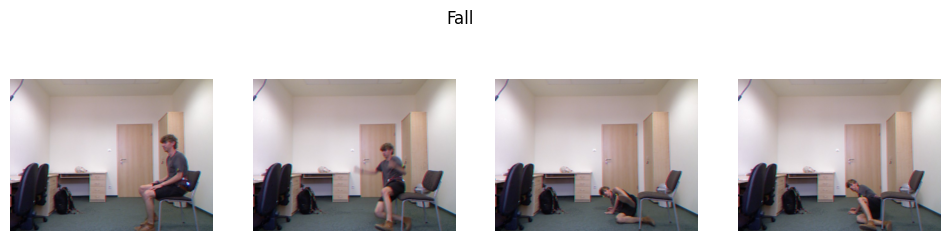

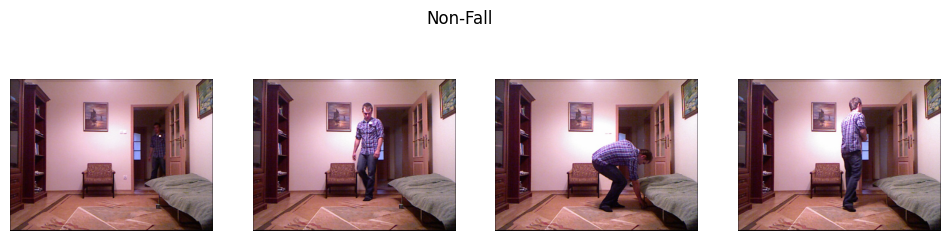

In [5]:
# TASK 1: Visual exploration of video sequences

import cv2
import matplotlib.pyplot as plt
import numpy as np

def show_sample(path, label):

    frames = []

    if os.path.isdir(path):

        files = sorted([
            f for f in os.listdir(path)
            if f.lower().endswith(image_extensions)
        ])

        selected = np.linspace(
            0, len(files)-1, min(4, len(files))
        ).astype(int)

        for idx in selected:

            img = cv2.imread(os.path.join(path, files[idx]))

            if img is not None:
                img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                frames.append(img)

    else:

        cap = cv2.VideoCapture(path)

        total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

        for idx in np.linspace(0, total-1, 4).astype(int):

            cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx))

            ret, frame = cap.read()

            if ret:
                frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                frames.append(frame)

        cap.release()

    plt.figure(figsize=(12, 3))

    for i, frame in enumerate(frames):

        plt.subplot(1, len(frames), i+1)
        plt.imshow(frame)
        plt.axis("off")

    title = "Fall" if label == 1 else "Non-Fall"

    plt.suptitle(title)
    plt.show()


# Display one sample of each category
fall_sample = next(x for x in dataset_info if x["label"] == 1)
adl_sample = next(x for x in dataset_info if x["label"] == 0)

show_sample(fall_sample["path"], 1)
show_sample(adl_sample["path"], 0)

In [6]:
# TASK 2: Frame extraction and preprocessing

import re

NUM_FRAMES = 16
IMG_SIZE = 112

# Natural sorting of image filenames
def natural_sort_key(text):

    return [
        int(c) if c.isdigit() else c.lower()
        for c in re.split(r'(\d+)', text)
    ]


# Function to extract frames
def extract_frames(path):

    frames = []

    # CASE 1: Image sequence folder
    if os.path.isdir(path):

        files = sorted([
            f for f in os.listdir(path)
            if f.lower().endswith(image_extensions)
        ], key=natural_sort_key)

        if len(files) == 0:
            return None

        indexes = np.linspace(
            0, len(files)-1, NUM_FRAMES
        ).astype(int)

        for idx in indexes:

            frame = cv2.imread(
                os.path.join(path, files[idx])
            )

            if frame is None:
                return None

            frame = cv2.cvtColor(
                frame, cv2.COLOR_BGR2RGB
            )

            frame = cv2.resize(
                frame, (IMG_SIZE, IMG_SIZE)
            )

            frames.append(frame)

    # CASE 2: Conventional video file
    else:

        cap = cv2.VideoCapture(path)

        total_frames = int(
            cap.get(cv2.CAP_PROP_FRAME_COUNT)
        )

        if not cap.isOpened() or total_frames <= 0:
            cap.release()
            return None

        indexes = np.linspace(
            0, total_frames-1, NUM_FRAMES
        ).astype(int)

        for idx in indexes:

            cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx))

            ret, frame = cap.read()

            if not ret:
                cap.release()
                return None

            frame = cv2.cvtColor(
                frame, cv2.COLOR_BGR2RGB
            )

            frame = cv2.resize(
                frame, (IMG_SIZE, IMG_SIZE)
            )

            frames.append(frame)

        cap.release()

    # Convert into normalized NumPy array
    frames = np.array(frames, dtype=np.float32)

    frames = frames / 255.0

    return frames

In [7]:
# TASK 2: Processing dataset and removing corrupted files

X_list = []
y_list = []
valid_paths = []

corrupted_files = []

for item in dataset_info:

    path = item["path"]
    label = item["label"]

    try:

        frames = extract_frames(path)

        if frames is not None and frames.shape == (
            NUM_FRAMES, IMG_SIZE, IMG_SIZE, 3
        ):

            X_list.append(frames)
            y_list.append(label)
            valid_paths.append(path)

        else:

            corrupted_files.append(path)

    except Exception as e:

        corrupted_files.append(path)
        print("Error:", path, e)


# Convert into NumPy arrays
X = np.array(X_list, dtype=np.float32)
y = np.array(y_list, dtype=np.int32)

print("Preprocessing completed!")

print("Video tensor shape:", X.shape)
print("Label shape:", y.shape)

print("Fall samples:", np.sum(y == 1))
print("Non-fall samples:", np.sum(y == 0))

print("Corrupted files:", len(corrupted_files))

Preprocessing completed!
Video tensor shape: (70, 16, 112, 112, 3)
Label shape: (70,)
Fall samples: 30
Non-fall samples: 40
Corrupted files: 0


In [8]:
# TASK 2: Train-validation-test splitting

from sklearn.model_selection import train_test_split

# First separate 15% for testing
X_train_val, X_test, y_train_val, y_test, paths_train_val, paths_test = train_test_split(
    X, y, valid_paths,
    test_size=0.15,
    random_state=42,
    stratify=y
)

# Separate 15% of total data for validation
X_train, X_val, y_train, y_val, paths_train, paths_val = train_test_split(
    X_train_val,
    y_train_val,
    paths_train_val,
    test_size=0.15/0.85,
    random_state=42,
    stratify=y_train_val
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

print("\nTraining class distribution:")
print("Fall:", np.sum(y_train == 1))
print("Non-Fall:", np.sum(y_train == 0))

print("\nFinal shapes:")
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

Training samples: 48
Validation samples: 11
Testing samples: 11

Training class distribution:
Fall: 20
Non-Fall: 28

Final shapes:
X_train: (48, 16, 112, 112, 3)
X_val: (11, 16, 112, 112, 3)
X_test: (11, 16, 112, 112, 3)


In [9]:
# TASK 2: Data augmentation and class balancing

import tensorflow as tf
from sklearn.utils.class_weight import compute_class_weight

# Data augmentation function
def augment_video(video, label):

    # Random horizontal flipping
    video = tf.cond(
        tf.random.uniform([]) > 0.5,
        lambda: tf.reverse(video, axis=[2]),
        lambda: video
    )

    # Random cropping (same crop for all frames)
    scale = tf.random.uniform([], 0.85, 1.0)

    crop_size = tf.cast(
        IMG_SIZE * scale, tf.int32
    )

    max_offset = IMG_SIZE - crop_size

    top = tf.random.uniform(
        [], 0, max_offset + 1, dtype=tf.int32
    )

    left = tf.random.uniform(
        [], 0, max_offset + 1, dtype=tf.int32
    )

    # Apply identical crop to each frame
    cropped = tf.map_fn(
        lambda frame: tf.image.crop_to_bounding_box(
            frame, top, left, crop_size, crop_size
        ),
        video
    )

    # Resize frames back to original size
    video = tf.image.resize(
        cropped, (IMG_SIZE, IMG_SIZE)
    )

    # Temporal jittering
    shift = tf.random.uniform(
        [], minval=-2, maxval=3, dtype=tf.int32
    )

    video = tf.roll(video, shift=shift, axis=0)

    return video, label


# Calculate class weights
classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

print("Class weights:", class_weights)


# Create TensorFlow datasets
BATCH_SIZE = 4

train_dataset = tf.data.Dataset.from_tensor_slices(
    (X_train, y_train)
)

train_dataset = (
    train_dataset
    .shuffle(len(X_train))
    .map(augment_video, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

val_dataset = tf.data.Dataset.from_tensor_slices(
    (X_val, y_val)
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

test_dataset = tf.data.Dataset.from_tensor_slices(
    (X_test, y_test)
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

print("Augmentation and data balancing completed!")

Class weights: {np.int32(0): np.float64(0.8571428571428571), np.int32(1): np.float64(1.2)}
Augmentation and data balancing completed!


In [10]:
# TASK 3: Building 3D CNN model

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv3D,
    MaxPooling3D,
    BatchNormalization,
    Dropout,
    Flatten,
    Dense,
    GlobalAveragePooling3D
)

model = Sequential([

    # Input layer
    tf.keras.layers.Input(
        shape=(NUM_FRAMES, IMG_SIZE, IMG_SIZE, 3)
    ),

    # First 3D convolution block
    Conv3D(16, (3, 3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling3D(pool_size=(1, 2, 2)),

    # Second 3D convolution block
    Conv3D(32, (3, 3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling3D(pool_size=(2, 2, 2)),

    # Third 3D convolution block
    Conv3D(64, (3, 3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling3D(pool_size=(2, 2, 2)),

    # Feature extraction
    GlobalAveragePooling3D(),

    # Fully connected layers
    Dense(64, activation='relu'),
    Dropout(0.5),

    # Binary classification
    Dense(1, activation='sigmoid')
])


# Compile model
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.AUC(name='auc')]
)


# Display architecture
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv3d (Conv3D)                 │ (None, 16, 112, 112,   │         1,312 │
│                                 │ 16)                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 16, 112, 112,   │            64 │
│ (BatchNormalization)            │ 16)                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d (MaxPooling3D)    │ (None, 16, 56, 56, 16) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_1 (Conv3D)               │ (None, 16, 56, 56, 32) │        13,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 56, 56, 32) │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_1 (MaxPooling3D)  │ (None, 8, 28, 28, 32)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_2 (Conv3D)               │ (None, 8, 28, 28, 64)  │        55,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 8, 28, 28, 64)  │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_2 (MaxPooling3D)  │ (None, 4, 14, 14, 64)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling3d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling3D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 75,201 (293.75 KB)

 Trainable params: 74,977 (292.88 KB)

 Non-trainable params: 224 (896.00 B)

In [12]:
# TASK 3: Training 3D CNN

from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Early stopping
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=7,
    restore_best_weights=True
)

# Reduce learning rate
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    min_lr=0.00001
)


# Train model
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=3,
    class_weight=class_weights,
    callbacks=[early_stop, reduce_lr]
)

Epoch 1/3
12/12 ━━━━━━━━━━━━━━━━━━━━ 52s 4s/step - accuracy: 0.7917 - auc: 0.8071 - loss: 0.4799 - val_accuracy: 0.4545 - val_auc: 0.7000 - val_loss: 0.6828 - learning_rate: 0.0010
Epoch 2/3
12/12 ━━━━━━━━━━━━━━━━━━━━ 46s 4s/step - accuracy: 0.7708 - auc: 0.8446 - loss: 0.4455 - val_accuracy: 0.8182 - val_auc: 0.7333 - val_loss: 0.6424 - learning_rate: 0.0010
Epoch 3/3
12/12 ━━━━━━━━━━━━━━━━━━━━ 46s 4s/step - accuracy: 0.8333 - auc: 0.9366 - loss: 0.3467 - val_accuracy: 0.4545 - val_auc: 0.7167 - val_loss: 0.7541 - learning_rate: 0.0010


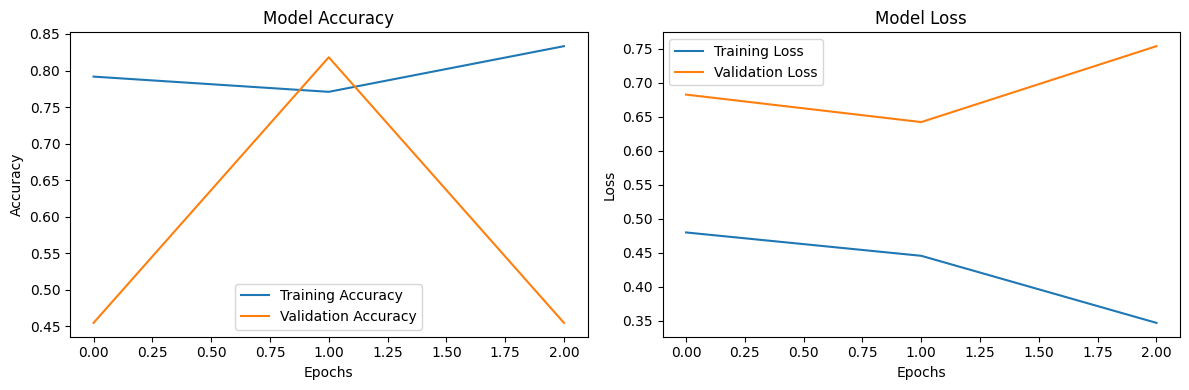

In [13]:
# TASK 3: Training and validation graphs

plt.figure(figsize=(12, 4))

# Accuracy graph
plt.subplot(1, 2, 1)

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title("Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()


# Loss graph
plt.subplot(1, 2, 2)

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title("Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [14]:
# TASK 3: Model evaluation

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Get prediction probabilities
y_prob = model.predict(test_dataset).flatten()

# Convert probabilities into binary classes
y_pred = (y_prob >= 0.5).astype(int)


# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, zero_division=0
)

recall = recall_score(
    y_test, y_pred, zero_division=0
)

f1 = f1_score(
    y_test, y_pred, zero_division=0
)

auc = roc_auc_score(y_test, y_prob)


print("MODEL PERFORMANCE")
print("-------------------------")

print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))
print("AUROC    :", round(auc, 4))

print("\nClassification Report:\n")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Non-Fall", "Fall"],
        zero_division=0
    )
)

3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 690ms/step
MODEL PERFORMANCE
-------------------------
Accuracy : 0.6364
Precision: 0.5556
Recall   : 1.0
F1 Score : 0.7143
AUROC    : 0.8333

Classification Report:

              precision    recall  f1-score   support

    Non-Fall       1.00      0.33      0.50         6
        Fall       0.56      1.00      0.71         5

    accuracy                           0.64        11
   macro avg       0.78      0.67      0.61        11
weighted avg       0.80      0.64      0.60        11



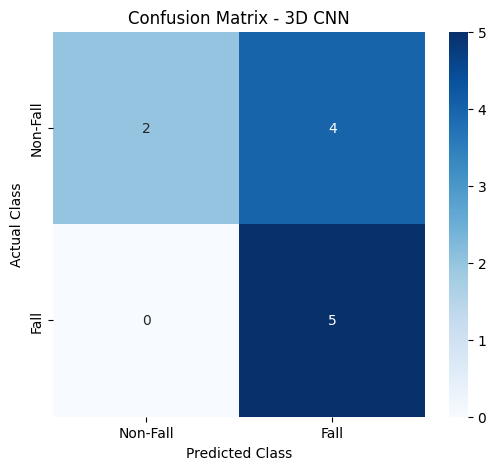

In [15]:
# TASK 3: Confusion matrix

from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Non-Fall', 'Fall'],
    yticklabels=['Non-Fall', 'Fall']
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.title("Confusion Matrix - 3D CNN")

plt.show()

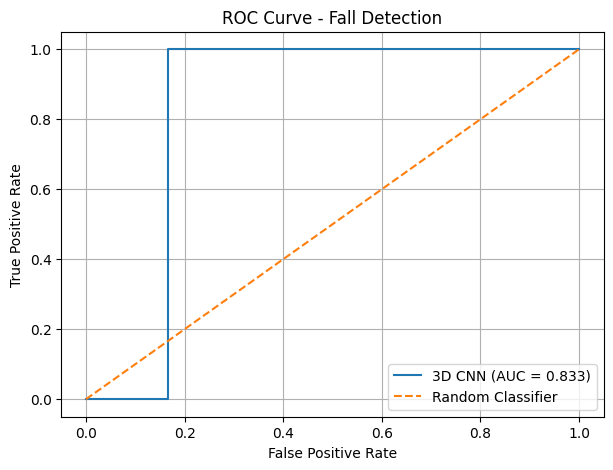

In [16]:
# TASK 3: ROC curve

from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(
    y_test, y_prob
)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr, tpr,
    label=f'3D CNN (AUC = {auc:.3f})'
)

plt.plot(
    [0, 1], [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve - Fall Detection")

plt.legend()
plt.grid()

plt.show()

Total misclassified videos: 4

Sequence: /root/.cache/kagglehub/datasets/shahliza27/ur-fall-detection-dataset/versions/1/UR_fall_detection_dataset_cam0_rgb/adl-36-cam0-rgb
Actual: Non-Fall
Predicted: Fall
Error Type: False Positive


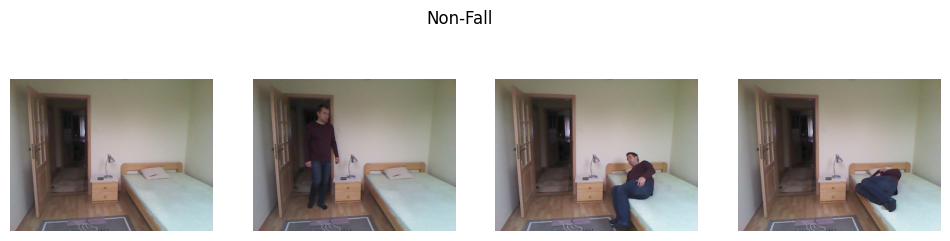


Sequence: /root/.cache/kagglehub/datasets/shahliza27/ur-fall-detection-dataset/versions/1/UR_fall_detection_dataset_cam0_rgb/adl-32-cam0-rgb
Actual: Non-Fall
Predicted: Fall
Error Type: False Positive


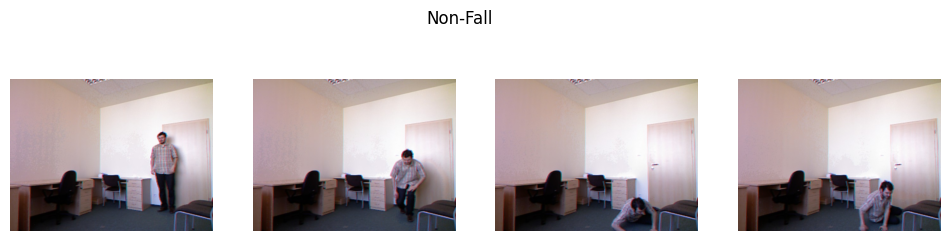


Sequence: /root/.cache/kagglehub/datasets/shahliza27/ur-fall-detection-dataset/versions/1/UR_fall_detection_dataset_cam0_rgb/adl-28-cam0-rgb
Actual: Non-Fall
Predicted: Fall
Error Type: False Positive


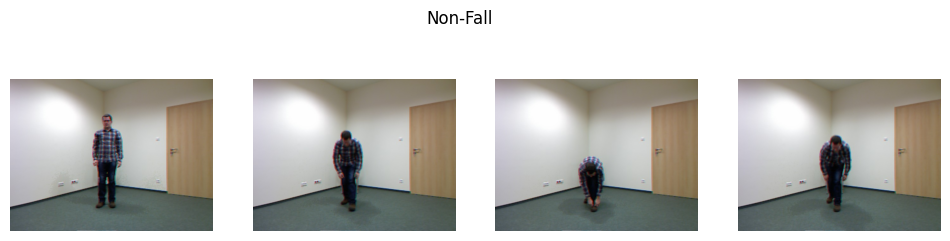


Sequence: /root/.cache/kagglehub/datasets/shahliza27/ur-fall-detection-dataset/versions/1/UR_fall_detection_dataset_cam0_rgb/adl-34-cam0-rgb
Actual: Non-Fall
Predicted: Fall
Error Type: False Positive


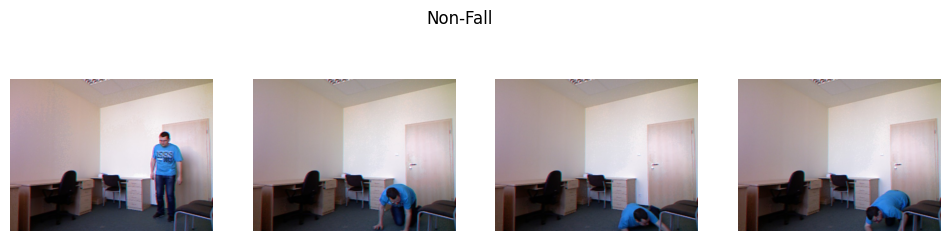

In [17]:
# TASK 3: Identifying misclassified sequences

misclassified = np.where(y_test != y_pred)[0]

print("Total misclassified videos:", len(misclassified))

for idx in misclassified:

    actual = "Fall" if y_test[idx] == 1 else "Non-Fall"

    predicted = "Fall" if y_pred[idx] == 1 else "Non-Fall"

    error_type = (
        "False Negative"
        if y_test[idx] == 1
        else "False Positive"
    )

    print("\nSequence:", paths_test[idx])
    print("Actual:", actual)
    print("Predicted:", predicted)
    print("Error Type:", error_type)

    # Display the misclassified sequence
    show_sample(paths_test[idx], y_test[idx])

In [18]:
# TASK 3: Saving trained 3D CNN model

model.save("/content/fall_detection_3dcnn.keras")

print("Model saved successfully!")

Model saved successfully!
